# Readiness Trigger — CMA Blob Data

Tests the readiness trigger threshold using CMA (China Meteorological Administration) Western North Pacific tropical cyclone track data from blob storage (`ds-cma-datasharing/cma_ftp/data_out/2004-2025_WNP_TC/`).

**Readiness threshold:** 1-minute sustained winds ≥ 177 kph (≈ 95.6 kt)

**Wind speed note:** CMA uses 2-minute sustained winds. Conversion before applying threshold:
> 177 kph (1-min) × 0.93 ≈ **164.6 kph (2-min) ≈ 88.9 kt** — this is what is applied to the data.

**Spatial approach:** Same as notebook 11 — consecutive track points connected into LineString segments. Only storms where a wind-speed-qualified segment crosses the actual land boundary of the target regions are counted (landfall only — no buffer).

In [1]:
import re
import io
import numpy as np
import pandas as pd
import geopandas as gpd
import matplotlib.pyplot as plt
import matplotlib.patches as mpatches
import matplotlib.lines as mlines
import matplotlib.colors as mcolors
import matplotlib.cm as cm
import ocha_stratus as stratus
from shapely.geometry import LineString, Point
from shapely.ops import unary_union

## Parameters

In [2]:
# Wind speed thresholds — CMA uses 2-minute sustained winds
THRESHOLD_KPH_1MIN = 177
THRESHOLD_KPH_2MIN = THRESHOLD_KPH_1MIN * 0.93       # 164.6 kph
THRESHOLD_KT       = THRESHOLD_KPH_2MIN / 1.852       # 88.9 kt — applied to CMA data

TEST_KPH_1MIN      = 192
TEST_KPH_2MIN      = round(TEST_KPH_1MIN * 0.93)      # 179 kph
TEST_KT            = TEST_KPH_1MIN * 0.93 / 1.852     # 96.4 kt

# Target regions
TARGET_REGIONS = ["PH02", "PH03", "PH05", "PH08"]

# Blob
CONTAINER   = "projects"
STAGE       = "dev"
BLOB_PREFIX = "ds-cma-datasharing/cma_ftp/data_out/2004-2025_WNP_TC/"

print(f"Threshold (1-min):  {THRESHOLD_KPH_1MIN} kph")
print(f"Threshold (2-min):  {THRESHOLD_KPH_2MIN:.1f} kph = {THRESHOLD_KT:.1f} kt (applied to CMA data)")
print(f"Test (1-min):       {TEST_KPH_1MIN} kph = {TEST_KPH_2MIN} kph (2-min) = {TEST_KT:.1f} kt")

Threshold (1-min):  177 kph
Threshold (2-min):  164.6 kph = 88.9 kt (applied to CMA data)
Test (1-min):       192 kph = 179 kph (2-min) = 96.4 kt


## Load Admin Boundaries

In [3]:
phl_admin_1 = stratus.codab.load_codab_from_fieldmaps(iso3="PHL", admin_level=1)
pcode_col = [c for c in phl_admin_1.columns if 'src' in c.lower()][0]
target_regions_gdf = phl_admin_1[phl_admin_1[pcode_col].isin(TARGET_REGIONS)].copy()
target_union = unary_union(target_regions_gdf.geometry)  # used for landfall checks
print(f"Target regions: {target_regions_gdf['adm1_name'].tolist()}")

Target regions: ['Region II (Cagayan Valley)', 'Region III (Central Luzon)', 'Region V (Bicol Region)', 'Region VIII (Eastern Visayas)']


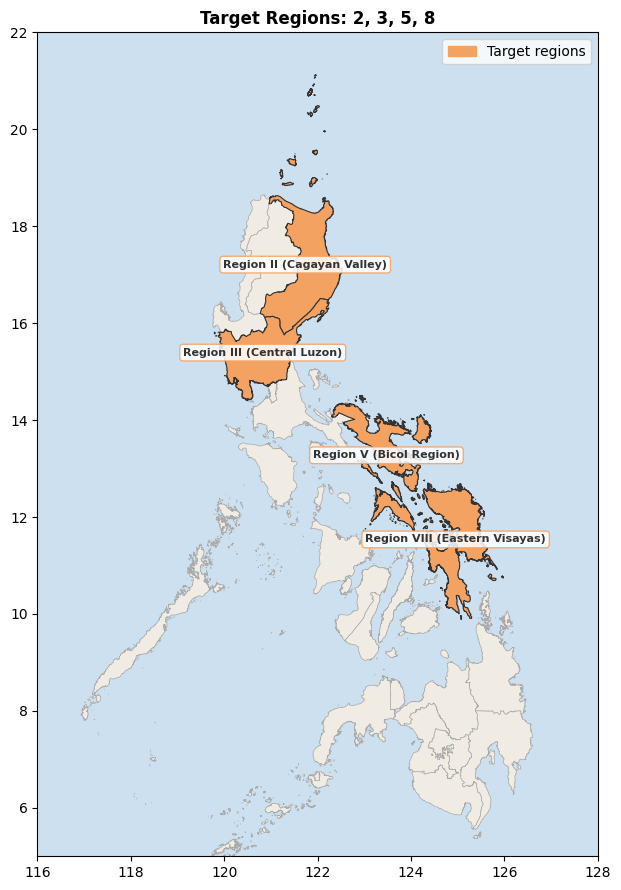

In [4]:
fig, ax = plt.subplots(figsize=(7, 9))
ax.set_facecolor("#cde0f0")
phl_admin_1.plot(ax=ax, color="#f0ece3", edgecolor="#aaa", linewidth=0.5)
target_regions_gdf.plot(ax=ax, color="#f4a261", edgecolor="#333", linewidth=0.8)
for _, row in target_regions_gdf.iterrows():
    centroid = row.geometry.centroid
    ax.annotate(
        row["adm1_name"], xy=(centroid.x, centroid.y),
        ha="center", va="center", fontsize=8, fontweight="bold", color="#333",
        bbox=dict(boxstyle="round,pad=0.3", fc="white", ec="#f4a261", alpha=0.85)
    )
ax.set_xlim(116, 128); ax.set_ylim(5, 22)
ax.set_title("Target Regions: 2, 3, 5, 8", fontweight="bold")
ax.legend(handles=[mpatches.Patch(color="#f4a261", label="Target regions")])
plt.tight_layout()
plt.show()

## Explore Blob Storage

In [5]:
# List all .dat files under the TC folder (filters out virtual directory entries)
all_blobs = stratus.list_container_blobs(
    name_starts_with=BLOB_PREFIX,
    stage=STAGE,
    container_name=CONTAINER,
)
blobs = [b for b in all_blobs if b.endswith(".dat")]
print(f"Total .dat files: {len(blobs)}\n")

year_folders = sorted({b.split("/")[-2] for b in blobs})
print(f"Years ({len(year_folders)}): {year_folders}\n")

sample_year = year_folders[0]
year_files  = [b for b in blobs if f"/{sample_year}/" in b]
print(f"Files in {sample_year} ({len(year_files)}):")
for f in year_files[:10]:
    print(" ", f)

Total .dat files: 540

Years (22): ['2004', '2005', '2006', '2007', '2008', '2009', '2010', '2011', '2012', '2013', '2014', '2015', '2016', '2017', '2018', '2019', '2020', '2021', '2022', '2023', '2024', '2025']

Files in 2004 (30):
  ds-cma-datasharing/cma_ftp/data_out/2004-2025_WNP_TC/2004/babj0401.dat
  ds-cma-datasharing/cma_ftp/data_out/2004-2025_WNP_TC/2004/babj0402.dat
  ds-cma-datasharing/cma_ftp/data_out/2004-2025_WNP_TC/2004/babj0403.dat
  ds-cma-datasharing/cma_ftp/data_out/2004-2025_WNP_TC/2004/babj0404.dat
  ds-cma-datasharing/cma_ftp/data_out/2004-2025_WNP_TC/2004/babj0405.dat
  ds-cma-datasharing/cma_ftp/data_out/2004-2025_WNP_TC/2004/babj0406.dat
  ds-cma-datasharing/cma_ftp/data_out/2004-2025_WNP_TC/2004/babj0407.dat
  ds-cma-datasharing/cma_ftp/data_out/2004-2025_WNP_TC/2004/babj0408.dat
  ds-cma-datasharing/cma_ftp/data_out/2004-2025_WNP_TC/2004/babj0409.dat
  ds-cma-datasharing/cma_ftp/data_out/2004-2025_WNP_TC/2004/babj0410.dat


In [6]:
# Print raw content of the first .dat file
sample_raw = stratus.load_blob_data(blobs[0], stage=STAGE, container_name=CONTAINER)
print(f"File: {blobs[0]}")
print(f"Size: {len(sample_raw):,} bytes\n")
print("--- Raw content ---")
print(sample_raw[:3000].decode("utf-8", errors="replace"))

File: ds-cma-datasharing/cma_ftp/data_out/2004-2025_WNP_TC/2004/babj0401.dat
Size: 15,657 bytes

--- Raw content ---
 diamond 7 2004���01̨��·�����й���
  SUDAL       0401 46                    184

 2004  04  05  08  00  149.1    8.4  998   18      200.0       0.0     270.0       5.0
 2004  04  05  08  24  147.7    8.6  990   23        0.0       0.0       0.0       0.0
 2004  04  05  08  48  146.3    9.0  980   30        0.0       0.0       0.0       0.0
 2004  04  05  08  72  144.3    9.7  975   33        0.0       0.0       0.0       0.0
 2004  04  05  14  00  148.9    8.7  990   23      250.0       0.0     292.5      10.0
 2004  04  05  14  24  147.1    9.2  980   30        0.0       0.0       0.0       0.0
 2004  04  05  14  48  145.1    9.7  970   35        0.0       0.0       0.0       0.0
 2004  04  05  14  72  142.4   10.3  960   40        0.0       0.0       0.0       0.0
 2004  04  05  20  00  148.6    9.3  990   23      300.0       0.0     292.5      10.0
 2004  04  05  20  2

In [7]:
def parse_cma_file(raw_bytes):
    """Parse a BABJ .dat file — keeps ALL forecast hours (FH=0,24,48,72).

    Columns:
      analysis_time  — when the bulletin was issued (YYYYMMDDHHMM string)
      fh             — forecast hour: 0=observed analysis, 24/48/72=forecast
      lon/lat        — position at this forecast hour
      wind_speed_kt  — 2-min kt (m/s × 1.944)

    FH=0 rows form the observed best-track (use for landfall detection).
    FH=24/48/72 rows are the CMA forecast from that bulletin (use for trigger check).
    """
    text = raw_bytes.decode("utf-8", errors="replace")
    records = []
    storm_id   = None
    storm_name = "UNNAMED"
    reading_meta = False

    for line in text.splitlines():
        stripped = line.strip()
        if not stripped:
            continue
        if stripped.startswith("diamond"):
            reading_meta = True
            storm_id, storm_name = None, "UNNAMED"
            continue
        if reading_meta:
            parts = stripped.split()
            if len(parts) >= 2:
                storm_name = parts[0]
                storm_id   = parts[1]
            reading_meta = False
            continue
        parts = stripped.split()
        if len(parts) < 9 or storm_id is None:
            continue
        try:
            records.append({
                "storm_id":      storm_id,
                "storm_name":    storm_name,
                "year":          int(parts[0]),
                "analysis_time": f"{parts[0]}{int(parts[1]):02d}{int(parts[2]):02d}{int(parts[3]):02d}00",
                "fh":            int(parts[4]),
                "lon":           float(parts[5]),
                "lat":           float(parts[6]),
                "wind_speed_kt": float(parts[8]) * 1.944,
            })
        except (ValueError, IndexError):
            continue

    return pd.DataFrame(records)

# Test on the sample file
sample_df = parse_cma_file(sample_raw)
print(f"Parsed {len(sample_df)} rows (all FH)")
print(sample_df.groupby("fh").size().rename("rows"))
print()
print(sample_df.head(8).to_string())

Parsed 179 rows (all FH)
fh
0     46
24    46
48    45
72    42
Name: rows, dtype: int64

  storm_id storm_name  year analysis_time  fh    lon   lat  wind_speed_kt
0     0401      SUDAL  2004  200404050800   0  149.1   8.4         34.992
1     0401      SUDAL  2004  200404050800  24  147.7   8.6         44.712
2     0401      SUDAL  2004  200404050800  48  146.3   9.0         58.320
3     0401      SUDAL  2004  200404050800  72  144.3   9.7         64.152
4     0401      SUDAL  2004  200404051400   0  148.9   8.7         44.712
5     0401      SUDAL  2004  200404051400  24  147.1   9.2         58.320
6     0401      SUDAL  2004  200404051400  48  145.1   9.7         68.040
7     0401      SUDAL  2004  200404051400  72  142.4  10.3         77.760


## Load All CMA Track Files

In [8]:
# ── Run once to parse all files and cache to blob ──────────────────────────
# Re-run if the parser changes. Comment out again after saving.

#all_dfs = []
#for blob in blobs:
#    raw = stratus.load_blob_data(blob, stage=STAGE, container_name=CONTAINER)
#    df  = parse_cma_file(raw)
#    if not df.empty:
#        all_dfs.append(df)

#tracks_raw = pd.concat(all_dfs, ignore_index=True)

#PARQUET_BLOB = "ds-cma-datasharing/processed/cma_wnp_tc_tracks.parquet"
#stratus.upload_parquet_to_blob(tracks_raw, PARQUET_BLOB, stage=STAGE, container_name=CONTAINER)
#print(f"Saved {len(tracks_raw):,} rows → {PARQUET_BLOB}")
#print(tracks_raw.groupby("fh").size().rename("rows"))

In [9]:
# ── Load from cached parquet ────────────────────────────────────────────────
PARQUET_BLOB = "ds-cma-datasharing/processed/cma_wnp_tc_tracks.parquet"
tracks_raw = stratus.load_parquet_from_blob(PARQUET_BLOB, stage=STAGE, container_name=CONTAINER)

# analysis_ts = when the bulletin was issued (same for FH=0,24,48,72 in the same block)
tracks_raw["analysis_ts"] = pd.to_datetime(tracks_raw["analysis_time"], format="%Y%m%d%H%M")

# GeoDataFrame with geometry for all rows (lon/lat of forecast position at each FH)
tracks = gpd.GeoDataFrame(
    tracks_raw,
    geometry=gpd.points_from_xy(tracks_raw["lon"], tracks_raw["lat"]),
    crs="EPSG:4326",
)

# Observed-only subset — used for landfall detection
tracks_obs = tracks[tracks["fh"] == 0].copy()

START_YEAR = int(tracks["year"].dropna().min())
END_YEAR   = int(tracks["year"].dropna().max())

print(f"Total rows (all FH): {len(tracks):,}")
print(f"Observed rows (FH=0): {len(tracks_obs):,}")
print(f"Unique storms: {tracks['storm_id'].nunique()}")
print(f"Years: {START_YEAR}–{END_YEAR}")
print(f"\nWind speed stats — FH=0 (kt):")
print(tracks_obs["wind_speed_kt"].describe())

Total rows (all FH): 114,197
Observed rows (FH=0): 27,992
Unique storms: 531
Years: 2004–2025

Wind speed stats — FH=0 (kt):
count    27992.000000
mean        59.978359
std         24.307974
min          0.000000
25%         38.880000
50%         54.432000
75%         77.760000
max        145.800000
Name: wind_speed_kt, dtype: float64


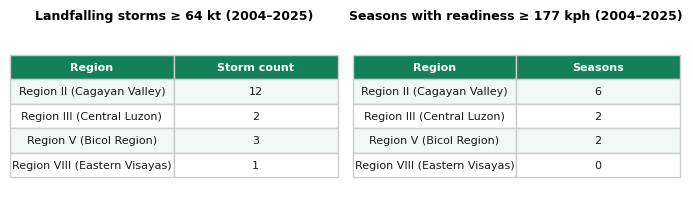

In [10]:
def count_storms_per_region(tracks_gdf, threshold_kt, store_storm_ids=False, count_seasons=False):
    """Count activations where, 4–7 days before qualifying landfall,
    any CMA forecast bulletin showed wind >= threshold at any forecast hour (FH=0/24/48/72).

    Landfall is detected from FH=0 observed positions only.
    Intensity check uses all FH rows of each bulletin in the window.
    """
    counts = []
    storm_region_map = {}
    for _, region_row in target_regions_gdf.iterrows():
        region_geom = region_row.geometry
        triggered_years = set()
        storm_count = 0
        for storm_id, grp_all in tracks_gdf.sort_values("analysis_time").groupby("storm_id"):
            grp_obs = grp_all[grp_all["fh"] == 0].reset_index(drop=True)
            year = grp_obs["year"].iloc[0]

            # Step 1: qualifying landfall from FH=0 track
            landfall_time = None
            for i in range(len(grp_obs) - 1):
                p0, p1 = grp_obs.iloc[i], grp_obs.iloc[i + 1]
                if pd.isna(p0["wind_speed_kt"]) or pd.isna(p1["wind_speed_kt"]):
                    continue
                if min(p0["wind_speed_kt"], p1["wind_speed_kt"]) < threshold_kt:
                    continue
                seg = LineString([(p0.geometry.x, p0.geometry.y), (p1.geometry.x, p1.geometry.y)])
                if seg.intersects(region_geom):
                    landfall_time = p0["analysis_ts"]
                    break

            if landfall_time is None:
                continue

            # Step 2: bulletins issued 4–7 days before landfall
            w_start = landfall_time - pd.Timedelta(days=7)
            w_end   = landfall_time - pd.Timedelta(days=4)
            bulletin_times = grp_obs[
                (grp_obs["analysis_ts"] >= w_start) & (grp_obs["analysis_ts"] <= w_end)
            ]["analysis_ts"].tolist()

            # Step 3: check if any forecast row in any such bulletin shows >= threshold
            triggered = False
            for bt in bulletin_times:
                bulletin_rows = grp_all[grp_all["analysis_ts"] == bt]
                if (bulletin_rows["wind_speed_kt"] >= threshold_kt).any():
                    triggered = True
                    break

            if not triggered:
                continue

            triggered_years.add(year)
            storm_count += 1
            if store_storm_ids:
                storm_region_map.setdefault(storm_id, []).append(region_row["adm1_name"])

        value = len(triggered_years) if count_seasons else storm_count
        counts.append({"Region": region_row["adm1_name"], "Count": value})
    return pd.DataFrame(counts), storm_region_map

def render_table(ax, df, title, col_label):
    display_df = df.rename(columns={"Count": col_label})
    ax.axis("off")
    ax.set_title(title, fontsize=9, fontweight="bold", pad=10)
    table = ax.table(cellText=display_df.values.tolist(), colLabels=list(display_df.columns),
                     loc="center", cellLoc="center")
    table.auto_set_font_size(False); table.set_fontsize(8); table.scale(1, 1.5)
    for (row, col), cell in table.get_celld().items():
        cell.set_edgecolor("#cccccc")
        if row == 0:
            cell.set_facecolor("#14805a"); cell.set_text_props(color="white", fontweight="bold")
        else:
            cell.set_facecolor(["#f0f7f4", "#ffffff"][(row - 1) % 2])
            cell.set_text_props(color="#1a1a1a")

df_64kt,    _                  = count_storms_per_region(tracks, 64)
df_readiness, storm_region_map = count_storms_per_region(
    tracks, THRESHOLD_KT, store_storm_ids=True, count_seasons=True
)

fig, axes = plt.subplots(1, 2, figsize=(7, 2.2))
render_table(axes[0], df_64kt,      f"Landfalling storms ≥ 64 kt ({START_YEAR}–{END_YEAR})", "Storm count")
render_table(axes[1], df_readiness, f"Seasons with readiness ≥ {THRESHOLD_KPH_1MIN} kph ({START_YEAR}–{END_YEAR})", "Seasons")
plt.tight_layout()
plt.show()

## Build Track Segments and Test Readiness Trigger

In [11]:
def build_triggered_storms(tracks_gdf, wind_threshold_kt, aoi):
    """Return one row per storm. triggered=True only if the storm made qualifying landfall
    AND any CMA bulletin issued 4–7 days before landfall showed >= threshold in any FH row."""
    results = []
    for storm_id, grp_all in tracks_gdf.sort_values("analysis_time").groupby("storm_id"):
        grp_all = grp_all.reset_index(drop=True)
        grp_obs = grp_all[grp_all["fh"] == 0].reset_index(drop=True)
        name = grp_all["storm_name"].iloc[0]
        year = grp_all["year"].iloc[0]

        # Step 1: qualifying landfall from FH=0 observed track
        landfall_time = None
        for i in range(len(grp_obs) - 1):
            p0, p1 = grp_obs.iloc[i], grp_obs.iloc[i + 1]
            w0, w1 = p0["wind_speed_kt"], p1["wind_speed_kt"]
            if pd.isna(w0) or pd.isna(w1):
                continue
            if min(w0, w1) < wind_threshold_kt:
                continue
            seg = LineString([(p0.geometry.x, p0.geometry.y), (p1.geometry.x, p1.geometry.y)])
            if seg.intersects(aoi):
                landfall_time = p0["analysis_ts"]
                break

        triggered = False
        trigger_wind = None
        if landfall_time is not None:
            # Step 2: bulletins issued 4–7 days before landfall
            w_start = landfall_time - pd.Timedelta(days=7)
            w_end   = landfall_time - pd.Timedelta(days=4)
            bulletin_times = grp_obs[
                (grp_obs["analysis_ts"] >= w_start) & (grp_obs["analysis_ts"] <= w_end)
            ]["analysis_ts"].tolist()

            # Step 3: check all FH rows (0/24/48/72) of each bulletin
            for bt in bulletin_times:
                bulletin_rows = grp_all[grp_all["analysis_ts"] == bt]
                qualifying = bulletin_rows[bulletin_rows["wind_speed_kt"] >= wind_threshold_kt]
                if not qualifying.empty:
                    triggered = True
                    trigger_wind = qualifying["wind_speed_kt"].max()
                    break

        results.append({
            "storm_id":        storm_id,
            "name":            name,
            "year":            year,
            "triggered":       triggered,
            "max_wind_kt":     grp_obs["wind_speed_kt"].max(),
            "max_wind_kph":    grp_obs["wind_speed_kt"].max() * 1.852,
            "trigger_wind_kt": trigger_wind,
        })
    return pd.DataFrame(results)

results   = build_triggered_storms(tracks, THRESHOLD_KT, target_union)
triggered = results[results["triggered"]].sort_values("max_wind_kph", ascending=False)
print(f"Total storms assessed: {len(results)}")
print(f"Storms triggering readiness (CMA forecast 4–7 days before landfall): {len(triggered)}")
print()
print(triggered[["name", "year", "max_wind_kph", "trigger_wind_kt"]].to_string())

Total storms assessed: 531
Storms triggering readiness (CMA forecast 4–7 days before landfall): 9

         name  year  max_wind_kph  trigger_wind_kt
158      MEGI  2010    259.220736           97.200
359      YUTU  2018    259.220736          116.640
307     HAIMA  2016    244.819584          126.360
355  MANGKHUT  2018    234.018720          116.640
466   DOKSURI  2023    223.217856           97.200
501    MAN-YI  2024    223.217856           93.312
265      NOUL  2015    216.017280           97.200
283     KOPPU  2015    198.015840          101.088
390   KAMMURI  2019    198.015840           97.200


## Return Period Summary

In [12]:
n_years = END_YEAR - START_YEAR + 1

# Test threshold (192 kph 1-min)
df_readiness_test, storm_region_map_test = count_storms_per_region(
    tracks, TEST_KT, store_storm_ids=True, count_seasons=True
)
results_test   = build_triggered_storms(tracks, TEST_KT, target_union)
triggered_test = results_test[results_test["triggered"]]

n_triggered_seasons      = triggered["year"].nunique()
n_triggered_seasons_test = triggered_test["year"].nunique()

def build_rp_df(df_region, n_seasons):
    rows = []
    for _, r in df_region.iterrows():
        count = r["Count"]
        rp = round(n_years / count, 1) if count > 0 else "—"
        rows.append({"Region": r["Region"], "Seasons": count, "RP (yrs)": rp})
    rows.append({
        "Region": "Overall (any region)",
        "Seasons": str(n_seasons),
        "RP (yrs)": round(n_years / n_seasons, 1) if n_seasons > 0 else "—",
    })
    return pd.DataFrame(rows)

rp_df      = build_rp_df(df_readiness,      n_triggered_seasons)
rp_df_test = build_rp_df(df_readiness_test, n_triggered_seasons_test)

print(f"Record: {n_years} years ({START_YEAR}–{END_YEAR}) | Once-per-season rule\n")
for label, df in [
    (f"{THRESHOLD_KPH_1MIN} kph (1-min) / {THRESHOLD_KPH_2MIN:.0f} kph (2-min)", rp_df),
    (f"{TEST_KPH_1MIN} kph (1-min) / {TEST_KPH_2MIN} kph (2-min) — PAGASA Typhoon", rp_df_test),
]:
    print(f"  {label}")
    print(df.to_string(index=False))
    print()

def render_rp_table(ax, df, title):
    ax.axis("off")
    ax.set_title(title, fontsize=8.5, fontweight="bold", pad=8)
    table = ax.table(cellText=df.values.tolist(), colLabels=list(df.columns),
                     loc="center", cellLoc="center")
    table.auto_set_font_size(False); table.set_fontsize(8); table.scale(1, 1.5)
    for (row, col), cell in table.get_celld().items():
        cell.set_edgecolor("#cccccc")
        if row == 0:
            cell.set_facecolor("#14805a"); cell.set_text_props(color="white", fontweight="bold")
        elif row == len(df):
            cell.set_facecolor("#d4edda"); cell.set_text_props(color="#1a1a1a", fontweight="bold")
        else:
            cell.set_facecolor(["#f0f7f4", "#ffffff"][(row - 1) % 2])
            cell.set_text_props(color="#1a1a1a")


Record: 22 years (2004–2025) | Once-per-season rule

  177 kph (1-min) / 165 kph (2-min)
                       Region Seasons RP (yrs)
   Region II (Cagayan Valley)       6      3.7
   Region III (Central Luzon)       2     11.0
      Region V (Bicol Region)       2     11.0
Region VIII (Eastern Visayas)       0        —
         Overall (any region)       7      3.1

  192 kph (1-min) / 179 kph (2-min) — PAGASA Typhoon
                       Region Seasons RP (yrs)
   Region II (Cagayan Valley)       6      3.7
   Region III (Central Luzon)       2     11.0
      Region V (Bicol Region)       1     22.0
Region VIII (Eastern Visayas)       0        —
         Overall (any region)       6      3.7



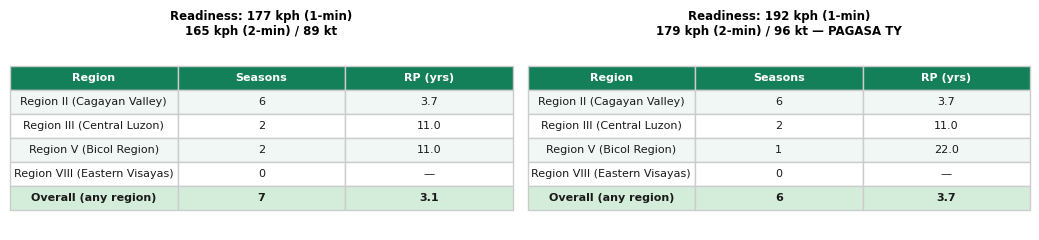

In [13]:

fig, axes = plt.subplots(1, 2, figsize=(10.5, 2.5))
render_rp_table(axes[0], rp_df,
    f"Readiness: {THRESHOLD_KPH_1MIN} kph (1-min)\n{THRESHOLD_KPH_2MIN:.0f} kph (2-min) / {THRESHOLD_KT:.0f} kt")
render_rp_table(axes[1], rp_df_test,
    f"Readiness: {TEST_KPH_1MIN} kph (1-min)\n{TEST_KPH_2MIN} kph (2-min) / {TEST_KT:.0f} kt — PAGASA TY")
plt.tight_layout()
plt.show()

## Wind Speed vs Return Period

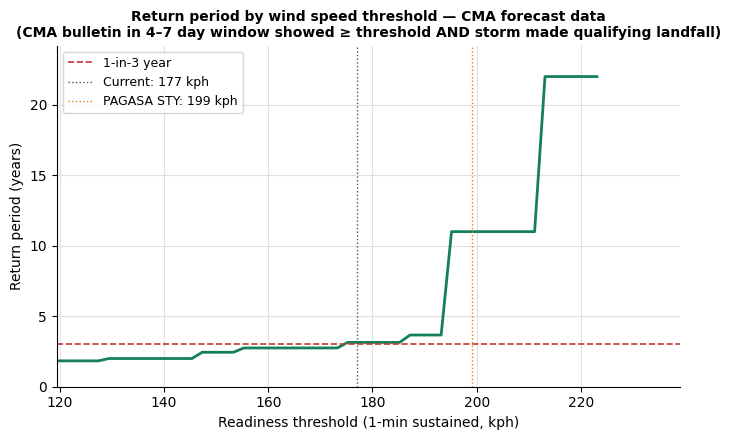

Current (177 kph 1-min): 7 seasons → RP 3.1 years
PAGASA STY (~199 kph 1-min): 2 seasons → RP 11.0 years

1-in-3 year RP: 175 kph (1-min) / 88 kt (2-min CMA)


In [14]:
# Per-storm: find qualifying landfall (≥ 60 kt, covers full sweep range),
# then check max forecast wind in the 4–7 day bulletin window (all FH rows)
storm_landfall = {}
for storm_id, grp_all in tracks.sort_values("analysis_time").groupby("storm_id"):
    grp_all = grp_all.reset_index(drop=True)
    grp_obs = grp_all[grp_all["fh"] == 0].reset_index(drop=True)
    year = grp_all["year"].iloc[0]

    landfall_wind = 0
    landfall_time = None
    for i in range(len(grp_obs) - 1):
        p0, p1 = grp_obs.iloc[i], grp_obs.iloc[i + 1]
        if pd.isna(p0["wind_speed_kt"]) or pd.isna(p1["wind_speed_kt"]):
            continue
        w = min(p0["wind_speed_kt"], p1["wind_speed_kt"])
        if w < 60:
            continue
        seg = LineString([(p0.geometry.x, p0.geometry.y), (p1.geometry.x, p1.geometry.y)])
        if seg.intersects(target_union):
            landfall_wind = w
            landfall_time = p0["analysis_ts"]
            break

    if landfall_time is None:
        continue

    # Max forecast wind across all FH rows of bulletins in 4–7 day window
    w_start = landfall_time - pd.Timedelta(days=7)
    w_end   = landfall_time - pd.Timedelta(days=4)
    bulletin_times = grp_obs[
        (grp_obs["analysis_ts"] >= w_start) & (grp_obs["analysis_ts"] <= w_end)
    ]["analysis_ts"].tolist()

    window_max = 0.0
    for bt in bulletin_times:
        bulletin_rows = grp_all[grp_all["analysis_ts"] == bt]
        bmax = bulletin_rows["wind_speed_kt"].max()
        if not pd.isna(bmax) and bmax > window_max:
            window_max = bmax

    storm_landfall[storm_id] = {
        "year":               year,
        "landfall_wind_kt":   landfall_wind,
        "window_max_wind_kt": window_max,
    }

# Sweep thresholds — trigger fires if landfall ≥ T AND any bulletin in 4-7d window showed ≥ T
thresholds_kt = np.arange(60, 121, 1)
rp_curve = np.array([
    n_years / len({v["year"] for v in storm_landfall.values()
                   if v["landfall_wind_kt"] >= T and v["window_max_wind_kt"] >= T})
    if any(v["landfall_wind_kt"] >= T and v["window_max_wind_kt"] >= T
           for v in storm_landfall.values()) else np.inf
    for T in thresholds_kt
])

thresholds_kph_1min = thresholds_kt / 0.93 * 1.852

CURRENT_KPH = THRESHOLD_KPH_1MIN
STY_KPH     = 100 / 0.93 * 1.852

fig, ax = plt.subplots(figsize=(7, 4.5))
finite_mask = np.isfinite(rp_curve)
ax.plot(thresholds_kph_1min[finite_mask], rp_curve[finite_mask], color="#14805a", linewidth=2)
ax.axhline(3, color="#c0392b", linewidth=1.2, linestyle="--", label="1-in-3 year")
ax.axvline(CURRENT_KPH, color="#555", linewidth=1, linestyle=":", label=f"Current: {int(CURRENT_KPH)} kph")
ax.axvline(STY_KPH, color="#e67e22", linewidth=1, linestyle=":", label=f"PAGASA STY: {STY_KPH:.0f} kph")
ax.set_xlabel("Readiness threshold (1-min sustained, kph)", fontsize=10)
ax.set_ylabel("Return period (years)", fontsize=10)
ax.set_title(
    "Return period by wind speed threshold — CMA forecast data\n"
    "(CMA bulletin in 4–7 day window showed ≥ threshold AND storm made qualifying landfall)",
    fontsize=10, fontweight="bold"
)
finite_rp = rp_curve[finite_mask]
ax.set_ylim(0, min(finite_rp.max() * 1.1, 40))
ax.set_xlim(thresholds_kph_1min[0], thresholds_kph_1min[-1])
ax.legend(fontsize=9)
ax.xaxis.grid(True, color="#e0e0e0", linewidth=0.8)
ax.yaxis.grid(True, color="#e0e0e0", linewidth=0.8)
ax.set_axisbelow(True)
ax.spines[["top", "right"]].set_visible(False)
plt.tight_layout()
plt.show()

for label, kph in [(f"Current ({THRESHOLD_KPH_1MIN} kph 1-min)", CURRENT_KPH),
                   (f"PAGASA STY (~{STY_KPH:.0f} kph 1-min)", STY_KPH)]:
    kt = kph * 0.93 / 1.852
    seasons = {v["year"] for v in storm_landfall.values()
               if v["landfall_wind_kt"] >= kt and v["window_max_wind_kt"] >= kt}
    rp = round(n_years / len(seasons), 1) if seasons else "—"
    print(f"{label}: {len(seasons)} seasons → RP {rp} years")

idx_3yr = np.where(rp_curve >= 3)[0]
if len(idx_3yr) > 0:
    kph_3yr = thresholds_kph_1min[idx_3yr[0]]
    kt_3yr  = thresholds_kt[idx_3yr[0]]
    print(f"\n1-in-3 year RP: {kph_3yr:.0f} kph (1-min) / {kt_3yr:.0f} kt (2-min CMA)")

## Return Period vs Lead Time

For storms that made a qualifying landfall, this shows how the return period changes depending on how far in advance the storm was already at threshold intensity. The 4–7 day readiness window is shaded.

Storms with qualifying landfall AND forecast at threshold: 23
Lead time range: 0.5–7.8 days

   storm_id  year  lead_days
13     1826  2018   7.750000
12     1822  2018   7.000000
8      1506  2015   6.500000
14     1928  2019   6.375000
4      1013  2010   4.625000
19     2305  2023   4.625000
11     1622  2016   4.625000
9      1524  2015   4.250000
21     2424  2024   4.125000
7      1330  2013   3.750000
10     1614  2016   3.416667
16     2114  2021   3.291667
17     2122  2021   3.000000
20     2422  2024   2.875000
15     2019  2020   2.500000
22     2425  2024   2.125000
3      0622  2006   1.750000
5      1111  2011   1.000000
18     2216  2022   1.000000
1      0620  2006   0.750000
6      1311  2013   0.500000
0      0402  2004   0.500000
2      0621  2006   0.500000


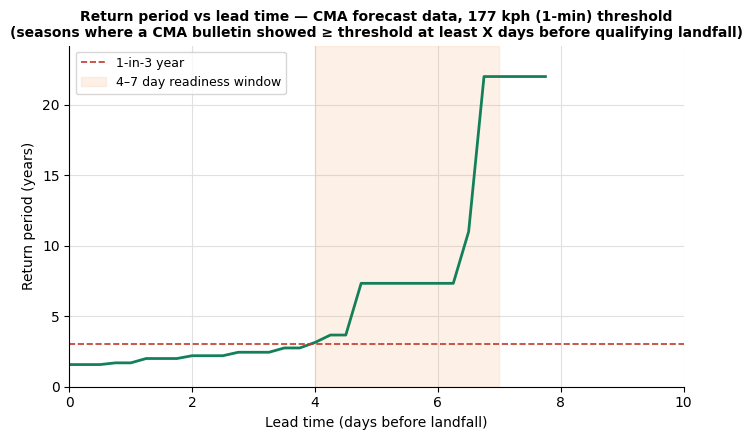

  At ≥ 4 days lead: 7 seasons → RP 3.1 years
  At ≥ 5 days lead: 3 seasons → RP 7.3 years
  At ≥ 6 days lead: 3 seasons → RP 7.3 years
  At ≥ 7 days lead: 1 seasons → RP 22.0 years


In [15]:
# For each storm with qualifying landfall, find the earliest CMA bulletin that
# showed >= THRESHOLD_KT in any FH row — that gives the maximum available lead time.
lead_records = []

for storm_id, grp_all in tracks.sort_values("analysis_time").groupby("storm_id"):
    grp_all = grp_all.reset_index(drop=True)
    grp_obs = grp_all[grp_all["fh"] == 0].reset_index(drop=True)
    year = grp_all["year"].iloc[0]

    # Qualifying landfall from FH=0 observed track
    landfall_time = None
    for i in range(len(grp_obs) - 1):
        p0, p1 = grp_obs.iloc[i], grp_obs.iloc[i + 1]
        if pd.isna(p0["wind_speed_kt"]) or pd.isna(p1["wind_speed_kt"]):
            continue
        if min(p0["wind_speed_kt"], p1["wind_speed_kt"]) < THRESHOLD_KT:
            continue
        seg = LineString([(p0.geometry.x, p0.geometry.y), (p1.geometry.x, p1.geometry.y)])
        if seg.intersects(target_union):
            landfall_time = p0["analysis_ts"]
            break

    if landfall_time is None:
        continue

    # Across all bulletins before landfall, find the earliest one where
    # any FH row showed >= threshold — that gives the maximum lead time
    pre_bulletins = sorted(grp_obs[grp_obs["analysis_ts"] < landfall_time]["analysis_ts"].tolist())
    max_lead = None
    for bt in pre_bulletins:
        bulletin_rows = grp_all[grp_all["analysis_ts"] == bt]
        if (bulletin_rows["wind_speed_kt"] >= THRESHOLD_KT).any():
            lead_days = (landfall_time - bt).total_seconds() / 86400
            if max_lead is None or lead_days > max_lead:
                max_lead = lead_days

    if max_lead is not None:
        lead_records.append({"year": year, "storm_id": storm_id, "lead_days": max_lead})

lead_df = pd.DataFrame(lead_records)
print(f"Storms with qualifying landfall AND forecast at threshold: {len(lead_df)}")
if not lead_df.empty:
    print(f"Lead time range: {lead_df['lead_days'].min():.1f}–{lead_df['lead_days'].max():.1f} days\n")
    print(lead_df[["storm_id", "year", "lead_days"]].sort_values("lead_days", ascending=False).to_string())

# RP at each minimum required lead time
# "How early did the CMA forecast reliably signal this storm at threshold?"
lead_range = np.arange(0, 10.25, 0.25)
rp_by_lead = np.array([
    n_years / lead_df[lead_df["lead_days"] >= L]["year"].nunique()
    if lead_df[lead_df["lead_days"] >= L]["year"].nunique() > 0 else np.inf
    for L in lead_range
])

fig, ax = plt.subplots(figsize=(7, 4.5))
finite_mask = np.isfinite(rp_by_lead)
ax.plot(lead_range[finite_mask], rp_by_lead[finite_mask], color="#14805a", linewidth=2)
ax.axhline(3, color="#c0392b", linewidth=1.2, linestyle="--", label="1-in-3 year")
ax.axvspan(4, 7, alpha=0.15, color="#f4a261", label="4–7 day readiness window")
ax.set_xlabel("Lead time (days before landfall)", fontsize=10)
ax.set_ylabel("Return period (years)", fontsize=10)
ax.set_title(
    f"Return period vs lead time — CMA forecast data, {THRESHOLD_KPH_1MIN} kph (1-min) threshold\n"
    "(seasons where a CMA bulletin showed ≥ threshold at least X days before qualifying landfall)",
    fontsize=10, fontweight="bold"
)
ax.set_xlim(0, 10)
ax.set_ylim(0, min(rp_by_lead[finite_mask].max() * 1.1, 40))
ax.legend(fontsize=9)
ax.xaxis.grid(True, color="#e0e0e0", linewidth=0.8)
ax.yaxis.grid(True, color="#e0e0e0", linewidth=0.8)
ax.set_axisbelow(True)
ax.spines[["top", "right"]].set_visible(False)
plt.tight_layout()
plt.show()

for L in [4, 5, 6, 7]:
    n = lead_df[lead_df["lead_days"] >= L]["year"].nunique()
    rp = round(n_years / n, 1) if n > 0 else "—"
    print(f"  At ≥ {L} days lead: {n} seasons → RP {rp} years")

## Readiness Activation by Season

In [16]:
triggered_177_years = set(triggered["year"].astype(int).tolist())
triggered_192_years = set(triggered_test["year"].astype(int).tolist())

region_short = {
    "Region II (Cagayan Valley)":    "Region 2",
    "Region III (Central Luzon)":    "Region 3",
    "Region V (Bicol Region)":       "Region 5",
    "Region VIII (Eastern Visayas)": "Region 8",
}

def build_year_details(triggered_df, srmap):
    details = {}
    for _, row in triggered_df.sort_values("year").iterrows():
        year = int(row["year"])
        regions = [region_short.get(r, r) for r in srmap.get(row["storm_id"], [])]
        entry = f"{row['name']} ({', '.join(regions)})" if regions else row["name"]
        details.setdefault(year, []).append(entry)
    return details

details_177 = build_year_details(triggered,      storm_region_map)
details_192 = build_year_details(triggered_test, storm_region_map_test)

rows = []
for year in range(START_YEAR, END_YEAR + 1):
    r177 = "✓  " + "  ·  ".join(details_177.get(year, [])) if year in triggered_177_years else "—"
    r192 = "✓  " + "  ·  ".join(details_192.get(year, [])) if year in triggered_192_years else "—"
    rows.append({
        "Year": year,
        f"{THRESHOLD_KPH_1MIN} kph (1-min) / {THRESHOLD_KPH_2MIN:.0f} kph (2-min)": r177,
        f"{TEST_KPH_1MIN} kph (1-min) / {TEST_KPH_2MIN} kph (2-min)": r192,
    })

df_timeline = pd.DataFrame(rows).set_index("Year")
with pd.option_context("display.max_colwidth", None, "display.max_rows", None):
    display(df_timeline)

,177 kph (1-min) / 165 kph (2-min),192 kph (1-min) / 179 kph (2-min)
Year,,
2004,—,—
2005,—,—
2006,—,—
2007,—,—
2008,—,—
2009,—,—
2010,✓ MEGI (Region 2),✓ MEGI (Region 2)
2011,—,—
2012,—,—
